# Transformers: Teoría, Arquitectura e Implementación

## Desde la Atención hasta BERT y GPT

**Objetivo**: Comprender en profundidad la arquitectura Transformer, sus fundamentos matemáticos,
su implementación desde cero con PyTorch, y cómo se derivan los modelos BERT y GPT.
Finalmente, utilizar librerías (Hugging Face) para ejemplos complejos del mundo real.

### Contenido
1. **Motivación**: Del RNN al Transformer
2. **Arquitectura**: "Attention Is All You Need"
3. **Matemáticas**: Atención, Positional Encoding, Multi-Head Attention
4. **Ejemplo numérico** paso a paso
5. **Implementación from scratch** con PyTorch
6. **BERT vs GPT**: Sub-modelos del Transformer
7. **Ejemplos con librerías**: Hugging Face Transformers

## 1. Motivación: ¿Por qué Transformers?

### El problema de los modelos secuenciales

Los modelos recurrentes (RNN, LSTM, GRU) procesan secuencias **paso a paso**:

```
x₁ → h₁ → x₂ → h₂ → x₃ → h₃ → ... → xₙ → hₙ
```

**Limitaciones fundamentales:**

| Problema | Descripción |
|----------|------------|
| **Secuencialidad** | No se puede paralelizar: cada paso depende del anterior |
| **Memoria a largo plazo** | Aunque LSTM mejora, sigue perdiendo información en secuencias largas |
| **Gradientes** | Vanishing/exploding gradients en backpropagation through time |
| **Velocidad** | O(n) pasos secuenciales para una secuencia de longitud n |

### La solución: Atención

En 2017, el paper **"Attention Is All You Need"** (Vaswani et al.) propuso eliminar
la recurrencia por completo y usar solo **mecanismos de atención**:

- ✅ **Paralelización total**: todos los tokens se procesan simultáneamente
- ✅ **Conexiones directas**: cualquier token puede "atender" a cualquier otro
- ✅ **Escalabilidad**: entrenamiento eficiente en GPUs/TPUs
- ✅ **Distancia constante**: la distancia entre cualquier par de tokens es O(1)

## 2. Arquitectura del Transformer

### Visión general

```
                    TRANSFORMER
    ┌─────────────────────────────────────────┐
    │                                         │
    │   ┌─────────────┐   ┌─────────────┐     │
    │   │   ENCODER   │   │   DECODER   │     │
    │   │             │   │             │     │
    │   │ ┌─────────┐ │   │ ┌─────────┐ │     │
    │   │ │Attention│ │   │ │ Masked  │ │     │
    │   │ │  + FFN  │ │──▶│ │Attention│ │     │
    │   │ │  × N    │ │   │ │+ Cross  │ │     │
    │   │ └─────────┘ │   │ │Attention│ │     │
    │   │             │   │ │+ FFN ×N │ │     │
    │   └──────▲──────┘   │ └────┬────┘ │     │
    │          │          └──────┼──────┘     │
    │          │                 │            │
    │     Input Emb +       Output Emb +      │
    │     Pos Encoding      Pos Encoding      │
    │          │                 │            │
    │      "Hola mundo"    "<start> Hello"    │
    └─────────────────────────────────────────┘
                                 │
                            "Hello world"
```

### Componentes principales

1. **Input Embedding + Positional Encoding**
2. **Multi-Head Self-Attention**
3. **Feed-Forward Network**
4. **Add & Norm (Residual + Layer Normalization)**
5. **Encoder Stack** (N capas idénticas)
6. **Decoder Stack** (N capas con Masked Attention + Cross-Attention)
7. **Linear + Softmax** (capa de salida)

## 3. Fundamentos Matemáticos

### 3.1 Embeddings de Entrada

Cada token se convierte en un vector denso de dimensión $d_{model}$:

$$\mathbf{x}_i = \text{Embedding}(\text{token}_i) \in \mathbb{R}^{d_{model}}$$

En el paper original, $d_{model} = 512$.

### 3.2 Positional Encoding (Codificación Posicional)

Como el Transformer no tiene recurrencia, necesitamos **inyectar información de posición**
explícitamente. Se usan funciones sinusoidales:

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

$$PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Donde:
- $pos$ = posición del token en la secuencia (0, 1, 2, ...)
- $i$ = índice de la dimensión del embedding (0, 1, ..., $d_{model}/2 - 1$)
- Cada dimensión corresponde a una sinusoide con diferente frecuencia

**¿Por qué sinusoides?**
- Permiten al modelo aprender a atender posiciones relativas
- $PE_{pos+k}$ puede expresarse como función lineal de $PE_{pos}$
- Las frecuencias van desde $2\pi$ hasta $10000 \cdot 2\pi$

La entrada final al encoder es:

$$\mathbf{z}_i = \text{Embedding}(\text{token}_i) + PE_i$$

### 3.3 Scaled Dot-Product Attention

El **corazón** del Transformer. Dada una secuencia de entrada, se generan tres matrices:

- **Q** (Query): "¿Qué estoy buscando?"
- **K** (Key): "¿Qué información tengo?"
- **V** (Value): "¿Qué valor devuelvo?"

$$Q = XW^Q, \quad K = XW^K, \quad V = XW^V$$

Donde $W^Q, W^K \in \mathbb{R}^{d_{model} \times d_k}$ y $W^V \in \mathbb{R}^{d_{model} \times d_v}$

La atención se calcula como:

$$\boxed{\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V}$$

**Paso a paso:**

1. **Similitud**: $S = QK^T$ → mide qué tan relevante es cada key para cada query
2. **Escalado**: $S' = S / \sqrt{d_k}$ → evita que los productos punto sean muy grandes
3. **Softmax**: $\alpha = \text{softmax}(S')$ → convierte scores en probabilidades (pesos de atención)
4. **Agregación**: $\text{output} = \alpha V$ → promedio ponderado de los values

**¿Por qué dividir por $\sqrt{d_k}$?**

Si $q$ y $k$ tienen componentes i.i.d. con media 0 y varianza 1:
$$\text{Var}(q \cdot k) = \sum_{i=1}^{d_k} \text{Var}(q_i \cdot k_i) = d_k$$

Al dividir por $\sqrt{d_k}$, la varianza se normaliza a 1, evitando que softmax sature.

### 3.4 Multi-Head Attention

En lugar de una sola atención, usamos **h cabezas** en paralelo:

$$\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, ..., \text{head}_h) W^O$$

Donde cada cabeza es:

$$\text{head}_i = \text{Attention}(QW_i^Q, KW_i^K, VW_i^V)$$

Con:
- $W_i^Q, W_i^K \in \mathbb{R}^{d_{model} \times d_k}$, $W_i^V \in \mathbb{R}^{d_{model} \times d_v}$
- $W^O \in \mathbb{R}^{hd_v \times d_{model}}$
- Típicamente: $d_k = d_v = d_{model} / h$

**¿Por qué múltiples cabezas?**
- Cada cabeza puede aprender **diferentes tipos de relaciones**:
  - Cabeza 1: relaciones sintácticas (sujeto-verbo)
  - Cabeza 2: relaciones de proximidad
  - Cabeza 3: relaciones semánticas
  - etc.

En el paper original: $h = 8$ cabezas, $d_k = d_v = 512/8 = 64$

### 3.5 Feed-Forward Network (FFN)

Después de la atención, cada posición pasa por una red feed-forward:

$$\text{FFN}(x) = \text{ReLU}(xW_1 + b_1)W_2 + b_2$$

Donde:
- $W_1 \in \mathbb{R}^{d_{model} \times d_{ff}}$ (expansión)
- $W_2 \in \mathbb{R}^{d_{ff} \times d_{model}}$ (proyección)
- $d_{ff} = 2048$ en el paper original (4× $d_{model}$)

La FFN se aplica **independientemente** a cada posición (mismos pesos para todas).

### 3.6 Residual Connection + Layer Normalization

Cada sub-capa tiene una conexión residual seguida de normalización:

$$\text{output} = \text{LayerNorm}(x + \text{Sublayer}(x))$$

**Layer Normalization:**

$$\text{LN}(x) = \frac{x - \mu}{\sigma + \epsilon} \cdot \gamma + \beta$$

Donde $\mu$ y $\sigma$ se calculan sobre las dimensiones del embedding (no del batch),
y $\gamma$, $\beta$ son parámetros aprendibles.

### 3.7 Máscaras en el Decoder

El decoder usa una **máscara causal** para evitar que los tokens "miren al futuro":

$$\text{mask}_{ij} = \begin{cases} 0 & \text{si } j \leq i \\ -\infty & \text{si } j > i \end{cases}$$

Esto se suma a los scores antes del softmax:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + \text{mask}\right)V$$

## 4. Ejemplo Numérico Paso a Paso

Veamos la atención con un ejemplo concreto usando una secuencia de 3 tokens
con dimensión $d_k = 4$.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

# --- Ejemplo numérico: Self-Attention ---
print("=" * 60)
print("EJEMPLO NUMÉRICO: SCALED DOT-PRODUCT ATTENTION")
print("=" * 60)

# Supongamos 3 tokens con embeddings de dimensión 4
# "El gato come"
X = np.array([
    [1.0, 0.0, 1.0, 0.0],   # "El"
    [0.0, 2.0, 0.0, 2.0],   # "gato"
    [1.0, 1.0, 1.0, 1.0],   # "come"
])
print(f"\nEntrada X (3 tokens × 4 dims):")
print(X)

# Matrices de proyección (simplificadas, normalmente son aprendidas)
W_Q = np.array([
    [1, 0, 1, 0],
    [1, 0, 0, 1],
    [0, 1, 1, 0],
    [0, 1, 0, 1],
]).T * 0.5

W_K = np.array([
    [0, 1, 1, 0],
    [1, 1, 0, 0],
    [0, 0, 1, 1],
    [1, 0, 1, 0],
]).T * 0.5

W_V = np.array([
    [1, 0, 0, 1],
    [0, 1, 1, 0],
    [1, 1, 0, 0],
    [0, 0, 1, 1],
]).T * 0.5

# Paso 1: Calcular Q, K, V
Q = X @ W_Q
K = X @ W_K
V = X @ W_V

print(f"\n--- Paso 1: Proyecciones ---")
print(f"Q = X · W_Q:\n{Q}")
print(f"\nK = X · W_K:\n{K}")
print(f"\nV = X · W_V:\n{V}")

# Paso 2: Scores = Q · K^T
d_k = Q.shape[-1]
scores = Q @ K.T
print(f"\n--- Paso 2: Scores = Q · Kᵀ ---")
print(f"Scores:\n{scores}")

# Paso 3: Escalado
scores_scaled = scores / np.sqrt(d_k)
print(f"\n--- Paso 3: Escalado por √d_k = √{d_k} = {np.sqrt(d_k):.2f} ---")
print(f"Scores escalados:\n{scores_scaled}")

# Paso 4: Softmax
def softmax(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / e_x.sum(axis=-1, keepdims=True)

attention_weights = softmax(scores_scaled)
print(f"\n--- Paso 4: Softmax (pesos de atención) ---")
print(f"α (cada fila suma 1):\n{attention_weights}")
print(f"Sumas por fila: {attention_weights.sum(axis=-1)}")

# Paso 5: Output = α · V
output = attention_weights @ V
print(f"\n--- Paso 5: Output = α · V ---")
print(f"Output:\n{output}")

# Interpretación
print(f"\n--- Interpretación ---")
tokens = ["El", "gato", "come"]
for i, token in enumerate(tokens):
    print(f'\nToken "{token}" atiende a:')
    for j, other in enumerate(tokens):
        print(f'  "{other}": {attention_weights[i][j]:.4f} ({attention_weights[i][j]*100:.1f}%)')

EJEMPLO NUMÉRICO: SCALED DOT-PRODUCT ATTENTION

Entrada X (3 tokens × 4 dims):
[[1. 0. 1. 0.]
 [0. 2. 0. 2.]
 [1. 1. 1. 1.]]

--- Paso 1: Proyecciones ---
Q = X · W_Q:
[[1.  0.5 0.5 0. ]
 [0.  1.  1.  2. ]
 [1.  1.  1.  1. ]]

K = X · W_K:
[[0.5 0.5 0.5 1. ]
 [1.  1.  1.  0. ]
 [1.  1.  1.  1. ]]

V = X · W_V:
[[0.5 0.5 0.5 0.5]
 [1.  1.  1.  1. ]
 [1.  1.  1.  1. ]]

--- Paso 2: Scores = Q · Kᵀ ---
Scores:
[[1.  2.  2. ]
 [3.  2.  4. ]
 [2.5 3.  4. ]]

--- Paso 3: Escalado por √d_k = √4 = 2.00 ---
Scores escalados:
[[0.5  1.   1.  ]
 [1.5  1.   2.  ]
 [1.25 1.5  2.  ]]

--- Paso 4: Softmax (pesos de atención) ---
α (cada fila suma 1):
[[0.2327 0.3837 0.3837]
 [0.3072 0.1863 0.5065]
 [0.2272 0.2918 0.481 ]]
Sumas por fila: [1. 1. 1.]

--- Paso 5: Output = α · V ---
Output:
[[0.8837 0.8837 0.8837 0.8837]
 [0.8464 0.8464 0.8464 0.8464]
 [0.8864 0.8864 0.8864 0.8864]]

--- Interpretación ---

Token "El" atiende a:
  "El": 0.2327 (23.3%)
  "gato": 0.3837 (38.4%)
  "come": 0.3837 (38.4%)

T

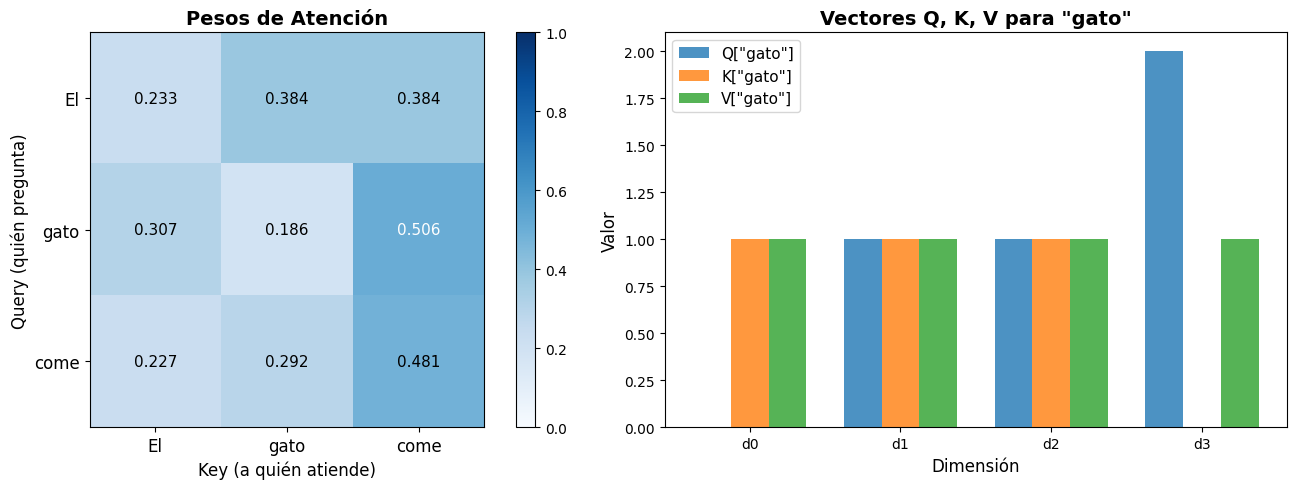

In [2]:
import matplotlib.pyplot as plt

# Visualizar los pesos de atención
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tokens = ["El", "gato", "come"]

# Mapa de calor de atención
im = axes[0].imshow(attention_weights, cmap='Blues', vmin=0, vmax=1)
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
axes[0].set_xticklabels(tokens, fontsize=12)
axes[0].set_yticklabels(tokens, fontsize=12)
axes[0].set_xlabel('Key (a quién atiende)', fontsize=12)
axes[0].set_ylabel('Query (quién pregunta)', fontsize=12)
axes[0].set_title('Pesos de Atención', fontsize=14, fontweight='bold')
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f'{attention_weights[i][j]:.3f}',
                    ha='center', va='center', fontsize=11,
                    color='white' if attention_weights[i][j] > 0.5 else 'black')
plt.colorbar(im, ax=axes[0])

# Visualizar Q, K, V como barras
x = np.arange(4)
width = 0.25
for idx, (mat, name) in enumerate([(Q, 'Q'), (K, 'K'), (V, 'V')]):
    axes[1].bar(x + idx*width - width, mat[1], width, label=f'{name}["gato"]', alpha=0.8)
axes[1].set_xlabel('Dimensión', fontsize=12)
axes[1].set_ylabel('Valor', fontsize=12)
axes[1].set_title('Vectores Q, K, V para "gato"', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'd{i}' for i in range(4)])

plt.tight_layout()
plt.show()

## 5. Visualización del Positional Encoding

Antes de implementar el Transformer completo, visualicemos cómo funciona
la codificación posicional con sinusoides.

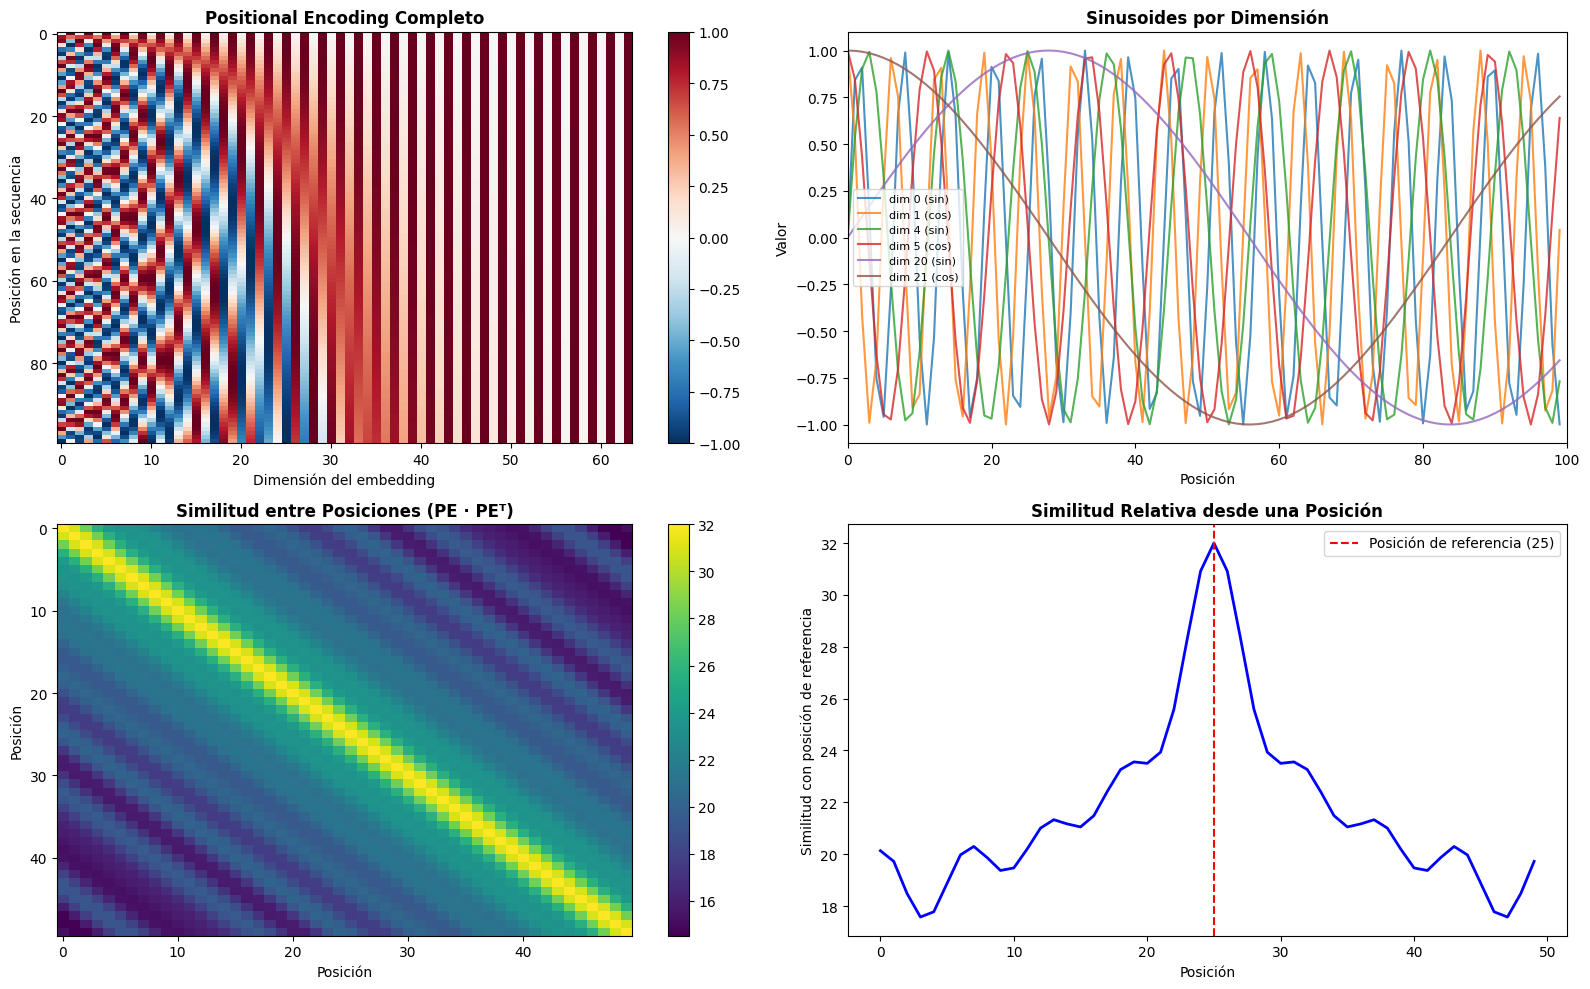


✅ El positional encoding captura relaciones posicionales:
   - Posiciones cercanas tienen alta similitud
   - La similitud decrece con la distancia
   - Las frecuencias bajas (dims altas) capturan posiciones globales
   - Las frecuencias altas (dims bajas) capturan posiciones locales


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def positional_encoding_numpy(max_len, d_model):
    """Genera la matriz de positional encoding."""
    PE = np.zeros((max_len, d_model))
    position = np.arange(max_len)[:, np.newaxis]  # (max_len, 1)
    div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))  # (d_model/2,)

    PE[:, 0::2] = np.sin(position * div_term)  # dimensiones pares: sin
    PE[:, 1::2] = np.cos(position * div_term)  # dimensiones impares: cos
    return PE

# Generar PE
max_len = 100
d_model = 64
PE = positional_encoding_numpy(max_len, d_model)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Mapa de calor completo
im = axes[0, 0].imshow(PE, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
axes[0, 0].set_xlabel('Dimensión del embedding')
axes[0, 0].set_ylabel('Posición en la secuencia')
axes[0, 0].set_title('Positional Encoding Completo', fontweight='bold')
plt.colorbar(im, ax=axes[0, 0])

# 2. Sinusoides individuales
for dim in [0, 1, 4, 5, 20, 21]:
    label = f'dim {dim} ({"sin" if dim % 2 == 0 else "cos"})'
    axes[0, 1].plot(PE[:, dim], label=label, alpha=0.8)
axes[0, 1].set_xlabel('Posición')
axes[0, 1].set_ylabel('Valor')
axes[0, 1].set_title('Sinusoides por Dimensión', fontweight='bold')
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_xlim(0, max_len)

# 3. Similitud entre posiciones
similarity = PE @ PE.T  # producto punto entre PEs
im2 = axes[1, 0].imshow(similarity[:50, :50], cmap='viridis', aspect='auto')
axes[1, 0].set_xlabel('Posición')
axes[1, 0].set_ylabel('Posición')
axes[1, 0].set_title('Similitud entre Posiciones (PE · PEᵀ)', fontweight='bold')
plt.colorbar(im2, ax=axes[1, 0])

# 4. Relación posicional relativa
pos_ref = 25
distances = []
for pos in range(50):
    dist = np.dot(PE[pos_ref], PE[pos])
    distances.append(dist)
axes[1, 1].plot(distances, 'b-', linewidth=2)
axes[1, 1].axvline(x=pos_ref, color='r', linestyle='--', label=f'Posición de referencia ({pos_ref})')
axes[1, 1].set_xlabel('Posición')
axes[1, 1].set_ylabel('Similitud con posición de referencia')
axes[1, 1].set_title('Similitud Relativa desde una Posición', fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("\n✅ El positional encoding captura relaciones posicionales:")
print("   - Posiciones cercanas tienen alta similitud")
print("   - La similitud decrece con la distancia")
print("   - Las frecuencias bajas (dims altas) capturan posiciones globales")
print("   - Las frecuencias altas (dims bajas) capturan posiciones locales")

## 6. Implementación From Scratch con PyTorch

Vamos a construir un Transformer completo **pieza por pieza**,
entendiendo cada componente antes de ensamblarlo.

### Arquitectura que implementaremos:

```
Encoder Layer:                    Decoder Layer:
┌──────────────────┐              ┌──────────────────────┐
│   Input          │              │   Input (shifted)     │
│      ↓           │              │      ↓                │
│ Multi-Head       │              │ Masked Multi-Head     │
│ Self-Attention   │              │ Self-Attention        │
│      ↓           │              │      ↓                │
│ Add & LayerNorm  │              │ Add & LayerNorm       │
│      ↓           │              │      ↓                │
│ Feed-Forward     │              │ Multi-Head Cross-     │
│ Network          │              │ Attention (enc→dec)   │
│      ↓           │              │      ↓                │
│ Add & LayerNorm  │              │ Add & LayerNorm       │
│      ↓           │              │      ↓                │
│   Output         │              │ Feed-Forward Network  │
└──────────────────┘              │      ↓                │
                                  │ Add & LayerNorm       │
                                  │      ↓                │
                                  │   Output              │
                                  └──────────────────────┘
```

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np
import matplotlib.pyplot as plt

# Verificar dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")
print(f"PyTorch version: {torch.__version__}")

Dispositivo: cpu
PyTorch version: 2.10.0+cpu


In [5]:
# =============================================================================
# COMPONENTE 1: Positional Encoding
# =============================================================================

class PositionalEncoding(nn.Module):
    """
    Codificación posicional con sinusoides.

    PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
    PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
    """

    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Crear matriz PE: (max_len, d_model)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )  # (d_model/2,)

        pe[:, 0::2] = torch.sin(position * div_term)  # dims pares
        pe[:, 1::2] = torch.cos(position * div_term)  # dims impares

        # Registrar como buffer (no es parámetro entrenable)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model) para broadcasting con batch
        self.register_buffer('pe', pe)

    def forward(self, x):
        """x: (batch_size, seq_len, d_model)"""
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)

# Verificación
pe = PositionalEncoding(d_model=16, max_len=50, dropout=0.0)
x_dummy = torch.zeros(1, 10, 16)  # batch=1, seq=10, d=16
out = pe(x_dummy)
print("Positional Encoding:")
print(f"  Entrada: {x_dummy.shape}")
print(f"  Salida:  {out.shape}")
print(f"  PE[0, :5, :4] =\n{out[0, :5, :4].numpy().round(4)}")

Positional Encoding:
  Entrada: torch.Size([1, 10, 16])
  Salida:  torch.Size([1, 10, 16])
  PE[0, :5, :4] =
[[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.311   0.9504]
 [ 0.9093 -0.4161  0.5911  0.8066]
 [ 0.1411 -0.99    0.8126  0.5828]
 [-0.7568 -0.6536  0.9536  0.3011]]


In [6]:
# =============================================================================
# COMPONENTE 2: Scaled Dot-Product Attention
# =============================================================================

def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Calcula la atención escalada por producto punto.

    Attention(Q, K, V) = softmax(QK^T / √d_k) · V

    Args:
        Q: (batch, heads, seq_len, d_k)
        K: (batch, heads, seq_len, d_k)
        V: (batch, heads, seq_len, d_v)
        mask: (batch, 1, 1, seq_len) o (batch, 1, seq_len, seq_len) opcional

    Returns:
        output: (batch, heads, seq_len, d_v)
        attention_weights: (batch, heads, seq_len, seq_len)
    """
    d_k = Q.size(-1)

    # Paso 1: QK^T → (batch, heads, seq_q, seq_k)
    scores = torch.matmul(Q, K.transpose(-2, -1))

    # Paso 2: Escalar por √d_k
    scores = scores / math.sqrt(d_k)

    # Paso 3: Aplicar máscara (opcional)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))

    # Paso 4: Softmax → pesos de atención
    attention_weights = F.softmax(scores, dim=-1)

    # Paso 5: Multiplicar por V
    output = torch.matmul(attention_weights, V)

    return output, attention_weights

# Verificación
batch, heads, seq_len, d_k = 1, 1, 4, 8
Q = torch.randn(batch, heads, seq_len, d_k)
K = torch.randn(batch, heads, seq_len, d_k)
V = torch.randn(batch, heads, seq_len, d_k)

out, weights = scaled_dot_product_attention(Q, K, V)
print("Scaled Dot-Product Attention:")
print(f"  Q, K, V shape: ({batch}, {heads}, {seq_len}, {d_k})")
print(f"  Output shape: {out.shape}")
print(f"  Weights shape: {weights.shape}")
print(f"  Weights sum per query: {weights.sum(dim=-1).squeeze()}")

# Con máscara causal
mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)
out_masked, weights_masked = scaled_dot_product_attention(Q, K, V, mask=mask)
print(f"\nCon máscara causal:")
print(f"  Weights (cada fila solo atiende a posiciones ≤ actual):")
print(f"  {weights_masked.squeeze().detach().numpy().round(3)}")

Scaled Dot-Product Attention:
  Q, K, V shape: (1, 1, 4, 8)
  Output shape: torch.Size([1, 1, 4, 8])
  Weights shape: torch.Size([1, 1, 4, 4])
  Weights sum per query: tensor([1.0000, 1.0000, 1.0000, 1.0000])

Con máscara causal:
  Weights (cada fila solo atiende a posiciones ≤ actual):
  [[1.    0.    0.    0.   ]
 [0.603 0.397 0.    0.   ]
 [0.486 0.395 0.119 0.   ]
 [0.323 0.355 0.292 0.03 ]]


In [7]:
# =============================================================================
# COMPONENTE 3: Multi-Head Attention
# =============================================================================

class MultiHeadAttention(nn.Module):
    """
    Multi-Head Attention: h cabezas de atención en paralelo.

    MultiHead(Q, K, V) = Concat(head_1, ..., head_h) · W_O
    head_i = Attention(Q·W_i^Q, K·W_i^K, V·W_i^V)
    """

    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model debe ser divisible por n_heads"

        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads  # dimensión por cabeza

        # Proyecciones lineales para Q, K, V y Output
        self.W_Q = nn.Linear(d_model, d_model, bias=False)
        self.W_K = nn.Linear(d_model, d_model, bias=False)
        self.W_V = nn.Linear(d_model, d_model, bias=False)
        self.W_O = nn.Linear(d_model, d_model, bias=False)

    def forward(self, query, key, value, mask=None):
        """
        Args:
            query: (batch, seq_q, d_model)
            key:   (batch, seq_k, d_model)
            value: (batch, seq_k, d_model)
            mask:  opcional

        En self-attention: query = key = value = X
        En cross-attention: query = decoder, key = value = encoder output
        """
        batch_size = query.size(0)

        # 1. Proyectar Q, K, V
        Q = self.W_Q(query)  # (batch, seq, d_model)
        K = self.W_K(key)
        V = self.W_V(value)

        # 2. Reshape para múltiples cabezas: (batch, seq, d_model) → (batch, n_heads, seq, d_k)
        Q = Q.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)

        # 3. Calcular atención
        attn_output, attn_weights = scaled_dot_product_attention(Q, K, V, mask)

        # 4. Concatenar cabezas: (batch, n_heads, seq, d_k) → (batch, seq, d_model)
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, -1, self.d_model
        )

        # 5. Proyección final
        output = self.W_O(attn_output)

        return output, attn_weights

# Verificación
d_model, n_heads = 32, 4
mha = MultiHeadAttention(d_model, n_heads)

x = torch.randn(2, 10, d_model)  # batch=2, seq=10
output, weights = mha(x, x, x)  # self-attention
print("Multi-Head Attention:")
print(f"  d_model={d_model}, n_heads={n_heads}, d_k={d_model//n_heads}")
print(f"  Input:  {x.shape}")
print(f"  Output: {output.shape}")
print(f"  Attention weights: {weights.shape}  (batch, heads, seq_q, seq_k)")

Multi-Head Attention:
  d_model=32, n_heads=4, d_k=8
  Input:  torch.Size([2, 10, 32])
  Output: torch.Size([2, 10, 32])
  Attention weights: torch.Size([2, 4, 10, 10])  (batch, heads, seq_q, seq_k)


In [8]:
# =============================================================================
# COMPONENTE 4: Feed-Forward Network
# =============================================================================

class FeedForward(nn.Module):
    """
    FFN(x) = ReLU(x·W₁ + b₁)·W₂ + b₂

    Expande la dimensión internamente (típicamente 4×) y luego proyecta de vuelta.
    """

    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

# =============================================================================
# COMPONENTE 5: Encoder Layer
# =============================================================================

class EncoderLayer(nn.Module):
    """
    Una capa del Encoder:
    1. Multi-Head Self-Attention + Add & Norm
    2. Feed-Forward + Add & Norm
    """

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attention = MultiHeadAttention(d_model, n_heads)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, src_mask=None):
        # Sub-capa 1: Self-Attention
        attn_output, attn_weights = self.self_attention(x, x, x, src_mask)
        x = self.norm1(x + self.dropout1(attn_output))  # Add & Norm

        # Sub-capa 2: Feed-Forward
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_output))  # Add & Norm

        return x, attn_weights

# =============================================================================
# COMPONENTE 6: Decoder Layer
# =============================================================================

class DecoderLayer(nn.Module):
    """
    Una capa del Decoder:
    1. Masked Multi-Head Self-Attention + Add & Norm
    2. Multi-Head Cross-Attention + Add & Norm
    3. Feed-Forward + Add & Norm
    """

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attention = MultiHeadAttention(d_model, n_heads)
        self.cross_attention = MultiHeadAttention(d_model, n_heads)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, x, enc_output, tgt_mask=None, src_mask=None):
        # Sub-capa 1: Masked Self-Attention (no puede ver el futuro)
        attn_output, self_attn_weights = self.self_attention(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout1(attn_output))

        # Sub-capa 2: Cross-Attention (query=decoder, key/value=encoder)
        cross_output, cross_attn_weights = self.cross_attention(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout2(cross_output))

        # Sub-capa 3: Feed-Forward
        ff_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout3(ff_output))

        return x, self_attn_weights, cross_attn_weights

# Verificación
d_model, n_heads, d_ff = 32, 4, 128

enc_layer = EncoderLayer(d_model, n_heads, d_ff)
dec_layer = DecoderLayer(d_model, n_heads, d_ff)

src = torch.randn(2, 10, d_model)  # source: batch=2, seq=10
tgt = torch.randn(2, 8, d_model)   # target: batch=2, seq=8

enc_out, _ = enc_layer(src)
dec_out, _, _ = dec_layer(tgt, enc_out)

print("Encoder Layer:")
print(f"  Input:  {src.shape}  →  Output: {enc_out.shape}")
print(f"\nDecoder Layer:")
print(f"  Target input: {tgt.shape}")
print(f"  Encoder output: {enc_out.shape}")
print(f"  Decoder output: {dec_out.shape}")

Encoder Layer:
  Input:  torch.Size([2, 10, 32])  →  Output: torch.Size([2, 10, 32])

Decoder Layer:
  Target input: torch.Size([2, 8, 32])
  Encoder output: torch.Size([2, 10, 32])
  Decoder output: torch.Size([2, 8, 32])


In [9]:
# =============================================================================
# COMPONENTE 7: Transformer Completo
# =============================================================================

class Transformer(nn.Module):
    """
    Transformer completo (Encoder-Decoder) para tareas seq-to-seq.

    Componentes:
    - Embedding + Positional Encoding (source y target)
    - Encoder Stack (N capas)
    - Decoder Stack (N capas)
    - Linear + Softmax (proyección al vocabulario)
    """

    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=64, n_heads=4,
                 n_layers=2, d_ff=256, max_len=100, dropout=0.1):
        super().__init__()

        self.d_model = d_model

        # Embeddings
        self.src_embedding = nn.Embedding(src_vocab_size, d_model)
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len, dropout)

        # Encoder y Decoder stacks
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])
        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])

        # Capa de salida
        self.fc_out = nn.Linear(d_model, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)

        # Inicialización de pesos (como en el paper)
        self._init_weights()

    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def generate_square_subsequent_mask(self, sz):
        """Genera máscara causal triangular inferior."""
        mask = torch.triu(torch.ones(sz, sz), diagonal=1).bool()
        return ~mask  # True donde se puede atender, False donde no

    def encode(self, src, src_mask=None):
        """Pasa la fuente por el encoder."""
        # Embedding + Positional Encoding
        x = self.src_embedding(src) * math.sqrt(self.d_model)
        x = self.positional_encoding(x)

        # Pasar por todas las capas del encoder
        attention_weights = []
        for layer in self.encoder_layers:
            x, attn_w = layer(x, src_mask)
            attention_weights.append(attn_w)

        return x, attention_weights

    def decode(self, tgt, enc_output, tgt_mask=None, src_mask=None):
        """Pasa el target por el decoder."""
        # Embedding + Positional Encoding
        x = self.tgt_embedding(tgt) * math.sqrt(self.d_model)
        x = self.positional_encoding(x)

        # Pasar por todas las capas del decoder
        self_attn_weights = []
        cross_attn_weights = []
        for layer in self.decoder_layers:
            x, self_w, cross_w = layer(x, enc_output, tgt_mask, src_mask)
            self_attn_weights.append(self_w)
            cross_attn_weights.append(cross_w)

        return x, self_attn_weights, cross_attn_weights

    def forward(self, src, tgt, src_mask=None, tgt_mask=None):
        """
        Forward pass completo.

        Args:
            src: (batch, src_seq_len) - tokens de entrada
            tgt: (batch, tgt_seq_len) - tokens de salida (shifted right)
        """
        # Máscara causal para el decoder
        if tgt_mask is None:
            tgt_mask = self.generate_square_subsequent_mask(tgt.size(1)).to(tgt.device)
            tgt_mask = tgt_mask.unsqueeze(0).unsqueeze(0)  # (1, 1, seq, seq)

        # Encoder
        enc_output, enc_attn = self.encode(src, src_mask)

        # Decoder
        dec_output, dec_self_attn, dec_cross_attn = self.decode(
            tgt, enc_output, tgt_mask, src_mask
        )

        # Proyección al vocabulario
        output = self.fc_out(dec_output)  # (batch, tgt_seq_len, tgt_vocab_size)

        return output, enc_attn, dec_self_attn, dec_cross_attn

# --- Verificación del Transformer completo ---
src_vocab, tgt_vocab = 100, 80
model = Transformer(
    src_vocab_size=src_vocab,
    tgt_vocab_size=tgt_vocab,
    d_model=64,
    n_heads=4,
    n_layers=2,
    d_ff=256
)

# Contar parámetros
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

src = torch.randint(0, src_vocab, (2, 12))   # batch=2, src_len=12
tgt = torch.randint(0, tgt_vocab, (2, 10))   # batch=2, tgt_len=10

output, _, _, _ = model(src, tgt)

print("=" * 60)
print("TRANSFORMER COMPLETO")
print("=" * 60)
print(f"\nArquitectura:")
print(f"  d_model = 64")
print(f"  n_heads = 4 (d_k = 16)")
print(f"  n_layers = 2")
print(f"  d_ff = 256")
print(f"  src_vocab = {src_vocab}, tgt_vocab = {tgt_vocab}")
print(f"\nParámetros totales: {total_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")
print(f"\nInput source: {src.shape}")
print(f"Input target: {tgt.shape}")
print(f"Output: {output.shape}  →  logits para vocabulario de {tgt_vocab} tokens")

TRANSFORMER COMPLETO

Arquitectura:
  d_model = 64
  n_heads = 4 (d_k = 16)
  n_layers = 2
  d_ff = 256
  src_vocab = 100, tgt_vocab = 80

Parámetros totales: 248,656
Parámetros entrenables: 248,656

Input source: torch.Size([2, 12])
Input target: torch.Size([2, 10])
Output: torch.Size([2, 10, 80])  →  logits para vocabulario de 80 tokens


## 7. Ejemplo de Entrenamiento: Invertir Secuencias

Para demostrar que nuestro Transformer from scratch **funciona**,
lo entrenaremos en una tarea sencilla: **invertir una secuencia de números**.

```
Entrada:  [1, 2, 3, 4, 5]
Salida:   [5, 4, 3, 2, 1]
```

Es una tarea simple pero que requiere que el modelo aprenda relaciones posicionales.

In [10]:
import torch
import torch.optim as optim
import time

# --- Configuración ---
VOCAB_SIZE = 12       # 0=PAD, 1=SOS, 2=EOS, 3-11=dígitos
SOS_TOKEN = 1
EOS_TOKEN = 2
PAD_TOKEN = 0
SEQ_LEN = 6           # longitud de la secuencia a invertir

# --- Generar datos ---
def generar_datos(n_samples, seq_len, vocab_min=3, vocab_max=11):
    """Genera pares (secuencia, secuencia invertida)."""
    src_data = []
    tgt_data = []

    for _ in range(n_samples):
        # Secuencia aleatoria de dígitos
        seq = torch.randint(vocab_min, vocab_max + 1, (seq_len,))

        # Source: secuencia + EOS
        src = torch.cat([seq, torch.tensor([EOS_TOKEN])])

        # Target: SOS + secuencia invertida + EOS
        tgt = torch.cat([torch.tensor([SOS_TOKEN]), seq.flip(0), torch.tensor([EOS_TOKEN])])

        src_data.append(src)
        tgt_data.append(tgt)

    return torch.stack(src_data), torch.stack(tgt_data)

# Generar datos
train_src, train_tgt = generar_datos(3000, SEQ_LEN)
test_src, test_tgt = generar_datos(500, SEQ_LEN)

print(f"Datos de entrenamiento: {train_src.shape[0]} muestras")
print(f"Datos de test: {test_src.shape[0]} muestras")
print(f"\nEjemplo:")
print(f"  Source:  {train_src[0].tolist()}")
print(f"  Target:  {train_tgt[0].tolist()}")
tokens_in = [str(x) for x in train_src[0].tolist()[:-1]]
tokens_out = [str(x) for x in train_tgt[0].tolist()[1:-1]]
print(f"  Tarea:   [{', '.join(tokens_in)}] → [{', '.join(tokens_out)}]")

Datos de entrenamiento: 3000 muestras
Datos de test: 500 muestras

Ejemplo:
  Source:  [4, 7, 11, 6, 4, 10, 2]
  Target:  [1, 10, 4, 6, 11, 7, 4, 2]
  Tarea:   [4, 7, 11, 6, 4, 10] → [10, 4, 6, 11, 7, 4]


In [11]:
# --- Modelo y entrenamiento ---
model = Transformer(
    src_vocab_size=VOCAB_SIZE,
    tgt_vocab_size=VOCAB_SIZE,
    d_model=64,
    n_heads=4,
    n_layers=2,
    d_ff=128,
    dropout=0.1
).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.98), eps=1e-9)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_TOKEN)

# --- Loop de entrenamiento ---
N_EPOCHS = 30
BATCH_SIZE = 64
losses = []

print("Entrenando Transformer from scratch...")
print("=" * 50)

start_time = time.time()

for epoch in range(N_EPOCHS):
    model.train()
    epoch_loss = 0
    n_batches = 0

    # Shuffle
    perm = torch.randperm(train_src.size(0))
    train_src_shuffled = train_src[perm]
    train_tgt_shuffled = train_tgt[perm]

    for i in range(0, len(train_src_shuffled), BATCH_SIZE):
        src_batch = train_src_shuffled[i:i+BATCH_SIZE].to(device)
        tgt_batch = train_tgt_shuffled[i:i+BATCH_SIZE].to(device)

        # Teacher forcing: input al decoder es tgt[:-1], label es tgt[1:]
        tgt_input = tgt_batch[:, :-1]   # SOS + secuencia (sin último token)
        tgt_label = tgt_batch[:, 1:]    # secuencia + EOS (sin SOS)

        # Forward
        output, _, _, _ = model(src_batch, tgt_input)

        # Loss
        output = output.reshape(-1, VOCAB_SIZE)
        tgt_label = tgt_label.reshape(-1)
        loss = criterion(output, tgt_label)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    avg_loss = epoch_loss / n_batches
    losses.append(avg_loss)

    if (epoch + 1) % 5 == 0:
        elapsed = time.time() - start_time
        print(f"Época {epoch+1:3d}/{N_EPOCHS} | Loss: {avg_loss:.4f} | Tiempo: {elapsed:.1f}s")

print(f"\nEntrenamiento completado en {time.time() - start_time:.1f}s")

Entrenando Transformer from scratch...
Época   5/30 | Loss: 0.4224 | Tiempo: 11.4s
Época  10/30 | Loss: 0.1219 | Tiempo: 25.8s
Época  15/30 | Loss: 0.0573 | Tiempo: 37.0s
Época  20/30 | Loss: 0.0329 | Tiempo: 47.6s
Época  25/30 | Loss: 0.0193 | Tiempo: 58.8s
Época  30/30 | Loss: 0.0136 | Tiempo: 70.1s

Entrenamiento completado en 70.1s


In [12]:
# --- Función de inferencia (autoregresiva) ---
@torch.no_grad()
def inferir(model, src_seq, max_len=20):
    """Genera la secuencia de salida token por token (greedy decoding)."""
    model.eval()

    src = src_seq.unsqueeze(0).to(device)  # (1, src_len)
    enc_output, _ = model.encode(src)

    # Empezar con SOS
    tgt_tokens = [SOS_TOKEN]

    for _ in range(max_len):
        tgt = torch.tensor([tgt_tokens]).to(device)  # (1, current_len)
        tgt_mask = model.generate_square_subsequent_mask(tgt.size(1)).to(device)
        tgt_mask = tgt_mask.unsqueeze(0).unsqueeze(0)

        dec_output, _, _ = model.decode(tgt, enc_output, tgt_mask)
        logits = model.fc_out(dec_output[:, -1, :])  # último token
        next_token = logits.argmax(dim=-1).item()

        tgt_tokens.append(next_token)

        if next_token == EOS_TOKEN:
            break

    return tgt_tokens

# --- Evaluación ---
model.eval()
correct = 0
total = len(test_src)

print("=" * 60)
print("EVALUACIÓN EN DATOS DE TEST")
print("=" * 60)

# Mostrar 10 ejemplos
print("\nEjemplos de predicción:")
print("-" * 50)
for i in range(10):
    src_seq = test_src[i]
    pred = inferir(model, src_seq)

    src_nums = src_seq[:-1].tolist()  # sin EOS
    expected = test_tgt[i][1:-1].tolist()  # sin SOS y EOS
    predicted = pred[1:-1] if pred[-1] == EOS_TOKEN else pred[1:]  # sin SOS y EOS

    match = "✅" if predicted == expected else "❌"
    if predicted == expected:
        correct += 1
    print(f"  Input: {src_nums} → Pred: {predicted} | Expected: {expected} {match}")

# Evaluar el resto
for i in range(10, total):
    src_seq = test_src[i]
    pred = inferir(model, src_seq)
    expected = test_tgt[i][1:-1].tolist()
    predicted = pred[1:-1] if len(pred) > 1 and pred[-1] == EOS_TOKEN else pred[1:]
    if predicted == expected:
        correct += 1

accuracy = correct / total * 100
print(f"\n{'=' * 50}")
print(f"Precisión en test: {correct}/{total} = {accuracy:.1f}%")
print(f"{'=' * 50}")

EVALUACIÓN EN DATOS DE TEST

Ejemplos de predicción:
--------------------------------------------------
  Input: [10, 8, 9, 5, 3, 10] → Pred: [10, 3, 5, 9, 8, 10] | Expected: [10, 3, 5, 9, 8, 10] ✅
  Input: [6, 7, 7, 8, 5, 3] → Pred: [3, 5, 8, 7, 7, 6] | Expected: [3, 5, 8, 7, 7, 6] ✅
  Input: [10, 11, 6, 8, 3, 11] → Pred: [11, 3, 8, 6, 11, 10] | Expected: [11, 3, 8, 6, 11, 10] ✅
  Input: [7, 8, 7, 7, 7, 11] → Pred: [11, 7, 7, 7, 8, 7] | Expected: [11, 7, 7, 7, 8, 7] ✅
  Input: [4, 7, 6, 3, 11, 11] → Pred: [11, 11, 3, 6, 7, 4] | Expected: [11, 11, 3, 6, 7, 4] ✅
  Input: [11, 5, 3, 11, 9, 8] → Pred: [8, 9, 11, 3, 5, 11] | Expected: [8, 9, 11, 3, 5, 11] ✅
  Input: [5, 10, 3, 10, 9, 3] → Pred: [3, 9, 10, 3, 10, 5] | Expected: [3, 9, 10, 3, 10, 5] ✅
  Input: [11, 6, 5, 5, 4, 4] → Pred: [4, 4, 5, 5, 6, 11] | Expected: [4, 4, 5, 5, 6, 11] ✅
  Input: [8, 9, 3, 11, 9, 5] → Pred: [5, 9, 11, 3, 9, 8] | Expected: [5, 9, 11, 3, 9, 8] ✅
  Input: [5, 5, 5, 6, 4, 8] → Pred: [8, 4, 6, 5, 5, 5] | Expec

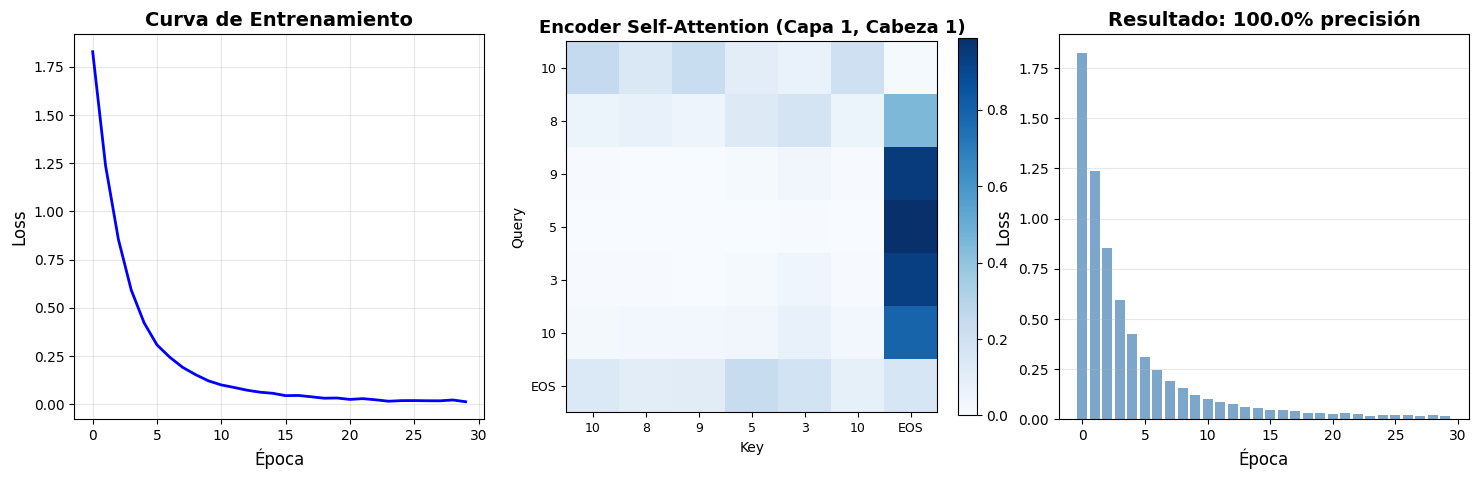

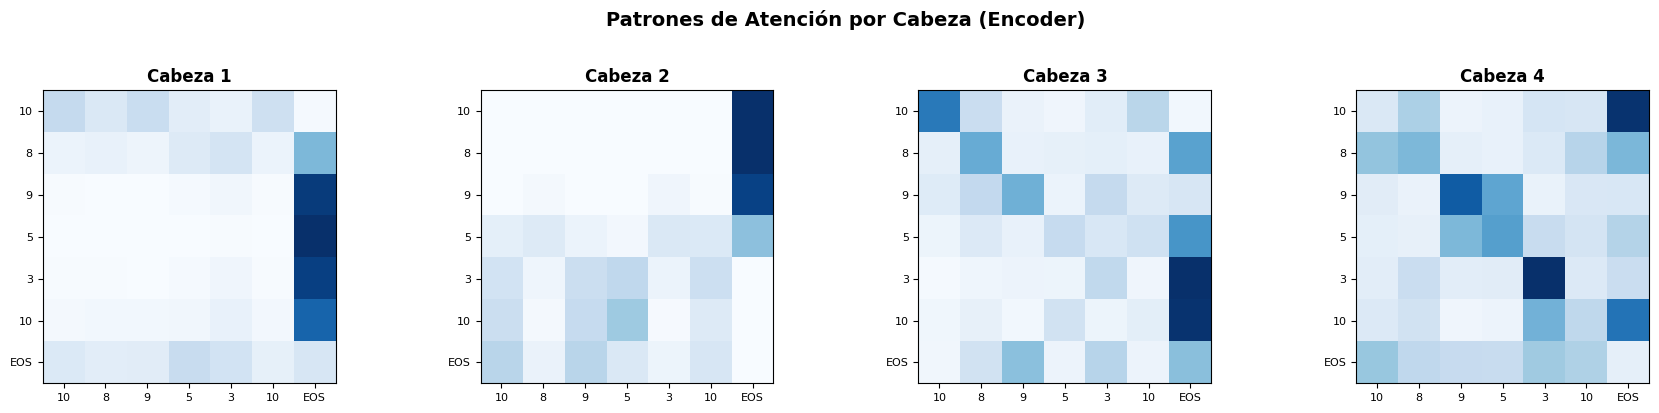


💡 Cada cabeza aprende patrones diferentes:
   - Algunas atienden a posiciones inversas (la tarea)
   - Otras capturan relaciones de proximidad
   - La diversidad de cabezas es clave para el poder del Transformer


In [14]:
# --- Visualización del entrenamiento y atención ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de pérdida
axes[0].plot(losses, 'b-', linewidth=2)
axes[0].set_xlabel('Época', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Curva de Entrenamiento', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. Visualizar atención del encoder
model.eval()
sample_idx = 0
src_seq = test_src[sample_idx].unsqueeze(0).to(device)
tgt_seq = test_tgt[sample_idx]
with torch.no_grad():
    output, enc_attn, _, _ = model(
        src_seq, tgt_seq[:-1].unsqueeze(0).to(device)
    )

# Atención de la primera capa, primera cabeza del encoder
attn = enc_attn[0][0, 0].cpu().numpy()  # (src_len, src_len)
src_tokens = [str(x) for x in test_src[sample_idx].tolist()]
src_tokens[-1] = 'EOS'

im = axes[1].imshow(attn, cmap='Blues', vmin=0)
axes[1].set_xticks(range(len(src_tokens)))
axes[1].set_yticks(range(len(src_tokens)))
axes[1].set_xticklabels(src_tokens, fontsize=9)
axes[1].set_yticklabels(src_tokens, fontsize=9)
axes[1].set_title('Encoder Self-Attention (Capa 1, Cabeza 1)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Key')
axes[1].set_ylabel('Query')
plt.colorbar(im, ax=axes[1], fraction=0.046)

# 3. Múltiples cabezas
fig2, axes2 = plt.subplots(1, 4, figsize=(18, 4))
for h in range(4):
    attn_h = enc_attn[0][0, h].cpu().numpy()
    im = axes2[h].imshow(attn_h, cmap='Blues', vmin=0)
    axes2[h].set_title(f'Cabeza {h+1}', fontsize=12, fontweight='bold')
    axes2[h].set_xticks(range(len(src_tokens)))
    axes2[h].set_xticklabels(src_tokens, fontsize=8)
    axes2[h].set_yticks(range(len(src_tokens)))
    axes2[h].set_yticklabels(src_tokens, fontsize=8)

# Usar el tercer subplot para un resumen
axes[2].bar(range(N_EPOCHS), losses, color='steelblue', alpha=0.7)
axes[2].set_xlabel('Época', fontsize=12)
axes[2].set_ylabel('Loss', fontsize=12)
axes[2].set_title(f'Resultado: {accuracy:.1f}% precisión', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
fig2.suptitle('Patrones de Atención por Cabeza (Encoder)', fontsize=14, fontweight='bold', y=1.02)
fig2.tight_layout()
plt.show()

print("\n💡 Cada cabeza aprende patrones diferentes:")
print("   - Algunas atienden a posiciones inversas (la tarea)")
print("   - Otras capturan relaciones de proximidad")
print("   - La diversidad de cabezas es clave para el poder del Transformer")

## 8. Sub-modelos: BERT y GPT

El Transformer original tiene **Encoder + Decoder**. Pero los modelos más exitosos
usan solo **una mitad**:

```
     TRANSFORMER ORIGINAL          BERT              GPT
    ┌──────┬──────────┐      ┌──────────┐      ┌──────────┐
    │      │          │      │          │      │          │
    │  E   │    D     │      │ ENCODER  │      │ DECODER  │
    │  N   │    E     │      │  ONLY    │      │  ONLY    │
    │  C   │    C     │      │          │      │          │
    │  O   │    O     │      │ Bidirec- │      │ Auto-    │
    │  D   │    D     │      │ cional   │      │ regresivo│
    │  E   │    E     │      │          │      │          │
    │  R   │    R     │      │ ← → ← →  │      │ → → → →  │
    │      │          │      │          │      │          │
    └──────┴──────────┘      └──────────┘      └──────────┘
      Traducción              Comprensión        Generación
      (seq2seq)               de texto           de texto
```

### 8.1 BERT (Bidirectional Encoder Representations from Transformers)

**Usa solo el Encoder** del Transformer.

**Características:**
- **Bidireccional**: cada token puede ver TODOS los demás tokens (izquierda Y derecha)
- **Pre-entrenamiento con MLM**: Masked Language Model
  - Se enmascara el 15% de los tokens aleatoriamente
  - El modelo debe predecir los tokens enmascarados
  - Ejemplo: "El [MASK] come pescado" → "gato"
- **Pre-entrenamiento con NSP**: Next Sentence Prediction
  - ¿La oración B sigue naturalmente a la oración A?

**Ideal para:**
- Clasificación de texto
- Named Entity Recognition (NER)
- Question Answering
- Análisis de sentimiento
- Similitud semántica

### 8.2 GPT (Generative Pre-trained Transformer)

**Usa solo el Decoder** del Transformer (sin cross-attention).

**Características:**
- **Autoregresivo (unidireccional)**: cada token solo ve los tokens ANTERIORES
- **Máscara causal**: impide ver el futuro
- **Pre-entrenamiento con CLM**: Causal Language Model
  - Predice el siguiente token dado el contexto anterior
  - P(token_t | token_1, ..., token_{t-1})
- **Generativo**: puede generar texto nuevo token por token

**Ideal para:**
- Generación de texto
- Completar texto
- Chatbots / Asistentes
- Traducción (zero-shot)
- Razonamiento (chain-of-thought)

### 8.3 Comparación Detallada

| Aspecto | BERT | GPT |
|---------|------|-----|
| **Arquitectura** | Solo Encoder | Solo Decoder |
| **Dirección** | Bidireccional (←→) | Unidireccional (→) |
| **Pre-entrenamiento** | MLM + NSP | CLM (next token) |
| **Atención** | Completa (todos ven a todos) | Causal (solo pasado) |
| **Fortaleza** | Comprensión profunda | Generación fluida |
| **Fine-tuning** | + capa de clasificación | Prompt engineering |
| **Tamaños** | BERT-base: 110M, BERT-large: 340M | GPT-2: 1.5B, GPT-3: 175B |
| **Tokenizer** | WordPiece | BPE (Byte Pair Encoding) |

### 8.4 Evolución de los modelos

```
2017: Transformer (Vaswani et al.) - "Attention Is All You Need"
  │
  ├── 2018: GPT-1 (OpenAI) - Decoder only, 117M parámetros
  │     └── 2019: GPT-2 - 1.5B parámetros
  │           └── 2020: GPT-3 - 175B parámetros
  │                 └── 2022: ChatGPT/GPT-3.5
  │                       └── 2023: GPT-4 (multimodal)
  │
  ├── 2018: BERT (Google) - Encoder only, 110M/340M
  │     ├── RoBERTa (Facebook) - BERT optimizado
  │     ├── ALBERT - BERT ligero
  │     ├── DistilBERT - BERT destilado (40% más pequeño)
  │     └── DeBERTa (Microsoft) - Disentangled attention
  │
  └── 2019: T5 (Google) - Encoder-Decoder, "text-to-text"
        └── 2022: FLAN-T5 - T5 con instruction tuning
```

### 8.5 ¿Cómo se conectan con el Transformer original?

- **BERT** = Stack de Encoder Layers (sin decoder, sin máscara causal)
- **GPT** = Stack de Decoder Layers (sin encoder, sin cross-attention, solo self-attention causal)
- **T5** = Transformer completo (encoder + decoder)

## 9. Implementación Simplificada: BERT vs GPT

Veamos las diferencias arquitectónicas implementadas.

In [15]:
# =============================================================================
# BERT simplificado (Encoder-only, bidireccional)
# =============================================================================

class BERTSimple(nn.Module):
    """
    BERT simplificado: solo usa el Encoder (atención bidireccional).
    Diseñado para tareas de clasificación/comprensión.
    """

    def __init__(self, vocab_size, d_model=64, n_heads=4, n_layers=2,
                 d_ff=256, max_len=512, n_classes=2, dropout=0.1):
        super().__init__()

        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len, dropout)

        # Stack de Encoder layers (bidireccional, sin máscara)
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])

        # Token especial [CLS] para clasificación
        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Tanh(),
            nn.Dropout(dropout),
            nn.Linear(d_model, n_classes)
        )

    def forward(self, x, mask=None):
        # Embedding + PE
        x = self.embedding(x) * math.sqrt(self.d_model)
        x = self.pos_encoding(x)

        # Encoder (BIDIRECCIONAL - sin máscara causal)
        for layer in self.encoder_layers:
            x, _ = layer(x, mask)  # ← No hay máscara causal!

        # Usar el primer token [CLS] para clasificación
        cls_output = x[:, 0, :]  # (batch, d_model)
        logits = self.classifier(cls_output)

        return logits

# =============================================================================
# GPT simplificado (Decoder-only, autoregresivo)
# =============================================================================

class GPTSimple(nn.Module):
    """
    GPT simplificado: solo usa el Decoder (atención causal/autoregresiva).
    Diseñado para generación de texto.
    """

    def __init__(self, vocab_size, d_model=64, n_heads=4, n_layers=2,
                 d_ff=256, max_len=512, dropout=0.1):
        super().__init__()

        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len, dropout)

        # Stack de Decoder layers (solo self-attention, SIN cross-attention)
        # Reutilizamos EncoderLayer pero CON máscara causal
        self.decoder_layers = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])

        self.layer_norm = nn.LayerNorm(d_model)
        self.fc_out = nn.Linear(d_model, vocab_size)

    def generate_causal_mask(self, seq_len):
        """Máscara triangular inferior: cada token solo ve el pasado."""
        mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
        return (~mask).unsqueeze(0).unsqueeze(0)  # (1, 1, seq, seq)

    def forward(self, x):
        seq_len = x.size(1)

        # Máscara CAUSAL (la diferencia clave con BERT)
        causal_mask = self.generate_causal_mask(seq_len).to(x.device)

        # Embedding + PE
        x = self.embedding(x) * math.sqrt(self.d_model)
        x = self.pos_encoding(x)

        # Decoder con máscara causal (UNIDIRECCIONAL)
        for layer in self.decoder_layers:
            x, _ = layer(x, causal_mask)  # ← Máscara causal!

        x = self.layer_norm(x)
        logits = self.fc_out(x)  # (batch, seq_len, vocab_size)

        return logits

    @torch.no_grad()
    def generar(self, inicio, max_tokens=50, temperatura=1.0):
        """Genera texto autoregresivamente."""
        self.eval()
        tokens = inicio.clone()

        for _ in range(max_tokens):
            logits = self(tokens)
            next_logits = logits[:, -1, :] / temperatura
            probs = F.softmax(next_logits, dim=-1)
            next_token = torch.multinomial(probs, 1)
            tokens = torch.cat([tokens, next_token], dim=1)

        return tokens

# --- Comparación ---
vocab_size = 1000

bert = BERTSimple(vocab_size, d_model=64, n_heads=4, n_layers=2, n_classes=3)
gpt = GPTSimple(vocab_size, d_model=64, n_heads=4, n_layers=2)

bert_params = sum(p.numel() for p in bert.parameters())
gpt_params = sum(p.numel() for p in gpt.parameters())

x = torch.randint(0, vocab_size, (1, 20))  # secuencia de 20 tokens

bert_out = bert(x)
gpt_out = gpt(x)

print("=" * 60)
print("COMPARACIÓN BERT vs GPT")
print("=" * 60)
print(f"\nBERT (Encoder-only, bidireccional):")
print(f"  Parámetros: {bert_params:,}")
print(f"  Input:  {x.shape} → Output: {bert_out.shape}")
print(f"  Salida: logits de clasificación (3 clases)")
print(f"  Atención: COMPLETA (cada token ve todos)")
print(f"\nGPT (Decoder-only, autoregresivo):")
print(f"  Parámetros: {gpt_params:,}")
print(f"  Input:  {x.shape} → Output: {gpt_out.shape}")
print(f"  Salida: logits de next-token para cada posición")
print(f"  Atención: CAUSAL (cada token solo ve los anteriores)")

COMPARACIÓN BERT vs GPT

BERT (Encoder-only, bidireccional):
  Parámetros: 167,811
  Input:  torch.Size([1, 20]) → Output: torch.Size([1, 3])
  Salida: logits de clasificación (3 clases)
  Atención: COMPLETA (cada token ve todos)

GPT (Decoder-only, autoregresivo):
  Parámetros: 228,584
  Input:  torch.Size([1, 20]) → Output: torch.Size([1, 20, 1000])
  Salida: logits de next-token para cada posición
  Atención: CAUSAL (cada token solo ve los anteriores)


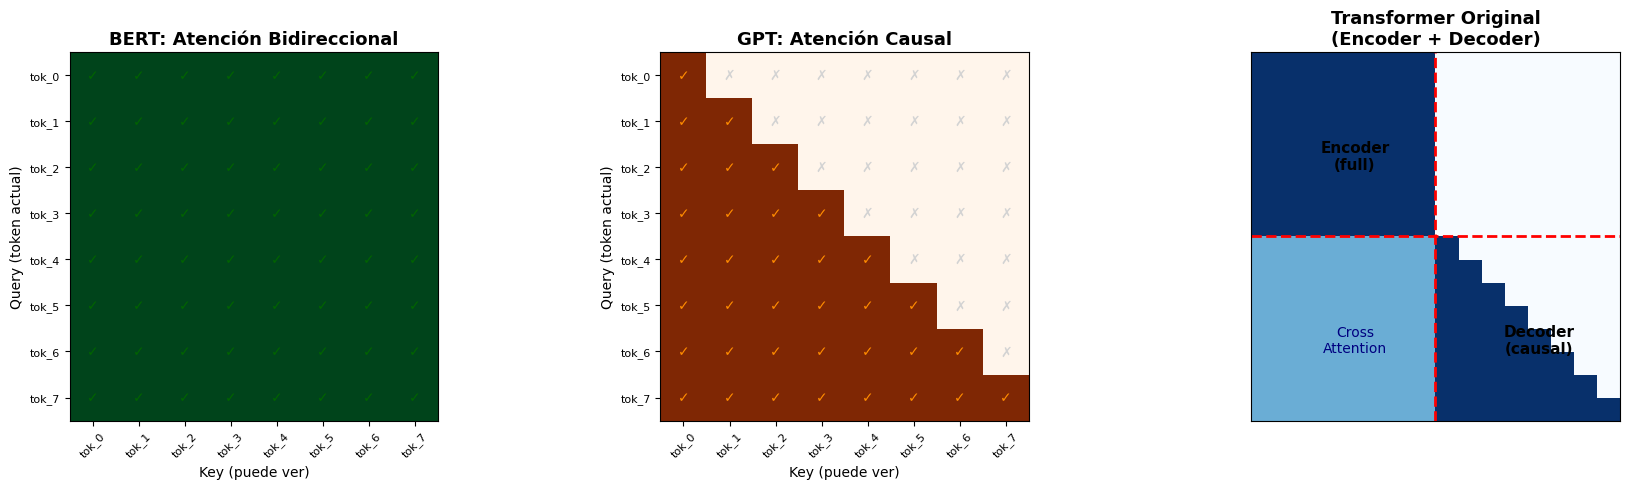


📌 Resumen de las diferencias:
   BERT  → Atención completa: cada token ve TODOS los demás
   GPT   → Atención causal: cada token solo ve los ANTERIORES
   T5    → Encoder (full) + Decoder (causal + cross-attention)


In [16]:
# --- Visualizar la diferencia en patrones de atención ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

seq_len = 8
tokens_label = [f'tok_{i}' for i in range(seq_len)]

# BERT: Atención completa (bidireccional)
bert_mask = np.ones((seq_len, seq_len))
im1 = axes[0].imshow(bert_mask, cmap='Greens', vmin=0, vmax=1)
axes[0].set_title('BERT: Atención Bidireccional', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Key (puede ver)')
axes[0].set_ylabel('Query (token actual)')
for i in range(seq_len):
    for j in range(seq_len):
        axes[0].text(j, i, '✓', ha='center', va='center', fontsize=10, color='darkgreen')
axes[0].set_xticks(range(seq_len))
axes[0].set_yticks(range(seq_len))
axes[0].set_xticklabels(tokens_label, fontsize=8, rotation=45)
axes[0].set_yticklabels(tokens_label, fontsize=8)

# GPT: Atención causal (unidireccional)
gpt_mask = np.tril(np.ones((seq_len, seq_len)))
im2 = axes[1].imshow(gpt_mask, cmap='Oranges', vmin=0, vmax=1)
axes[1].set_title('GPT: Atención Causal', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Key (puede ver)')
axes[1].set_ylabel('Query (token actual)')
for i in range(seq_len):
    for j in range(seq_len):
        symbol = '✓' if j <= i else '✗'
        color = 'darkorange' if j <= i else 'lightgray'
        axes[1].text(j, i, symbol, ha='center', va='center', fontsize=10, color=color)
axes[1].set_xticks(range(seq_len))
axes[1].set_yticks(range(seq_len))
axes[1].set_xticklabels(tokens_label, fontsize=8, rotation=45)
axes[1].set_yticklabels(tokens_label, fontsize=8)

# Transformer original: Encoder full + Decoder causal con cross
combined = np.zeros((seq_len * 2, seq_len * 2))
combined[:seq_len, :seq_len] = 1  # Encoder: full
combined[seq_len:, seq_len:] = np.tril(np.ones((seq_len, seq_len)))  # Decoder: causal
combined[seq_len:, :seq_len] = 0.5  # Cross-attention
im3 = axes[2].imshow(combined, cmap='Blues', vmin=0, vmax=1)
axes[2].set_title('Transformer Original\n(Encoder + Decoder)', fontsize=13, fontweight='bold')
axes[2].axhline(y=seq_len-0.5, color='red', linewidth=2, linestyle='--')
axes[2].axvline(x=seq_len-0.5, color='red', linewidth=2, linestyle='--')
axes[2].text(seq_len//2, seq_len//2, 'Encoder\n(full)', ha='center', va='center', fontsize=11, fontweight='bold')
axes[2].text(seq_len + seq_len//2, seq_len + seq_len//2, 'Decoder\n(causal)', ha='center', va='center', fontsize=11, fontweight='bold')
axes[2].text(seq_len//2, seq_len + seq_len//2, 'Cross\nAttention', ha='center', va='center', fontsize=10, color='navy')
axes[2].set_xticks([])
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

print("\n📌 Resumen de las diferencias:")
print("   BERT  → Atención completa: cada token ve TODOS los demás")
print("   GPT   → Atención causal: cada token solo ve los ANTERIORES")
print("   T5    → Encoder (full) + Decoder (causal + cross-attention)")

## 10. Ejemplos con Librerías: Hugging Face Transformers

Ahora usaremos la librería `transformers` de Hugging Face para ejemplos
del mundo real con modelos pre-entrenados.

> **Nota**: Estos modelos están pre-entrenados en enormes cantidades de texto
> y disponibles gratuitamente.

In [17]:
# Instalar dependencias
# !pip install transformers torch sentencepiece -q

# Verificar instalación
try:
    import transformers
    print(f"✅ transformers version: {transformers.__version__}")
except ImportError:
    print("⚠️ Instalando transformers...")
    import subprocess
    subprocess.check_call(['pip', 'install', 'transformers', 'sentencepiece', '-q'])
    import transformers
    print(f"✅ transformers instalado: {transformers.__version__}")

print(f"✅ torch version: {torch.__version__}")

✅ transformers version: 5.0.0
✅ torch version: 2.10.0+cpu


### 10.1 Ejemplo: Pipeline de Análisis de Sentimiento (BERT)

El pipeline más simple de Hugging Face. Usa un modelo BERT fine-tuneado para
clasificar el sentimiento de un texto.

In [19]:
from transformers import pipeline

# --- Análisis de Sentimiento ---
print("=" * 60)
print("ANÁLISIS DE SENTIMIENTO (BERT)")
print("=" * 60)

# Crear pipeline (descarga modelo automáticamente)
clasificador = pipeline("sentiment-analysis")

# Textos de ejemplo
textos = [
    "I love this movie, it's absolutely fantastic!",
    "This is the worst experience I've ever had.",
    "The weather is okay today, nothing special.",
    "I'm so excited about the new project!",
    "The food was terrible and the service was slow.",
]

print("\nResultados:")
print("-" * 50)
for texto in textos:
    resultado = clasificador(texto)[0]
    emoji = "😊" if resultado['label'] == 'POSITIVE' else "😞"
    print(f"{emoji} [{resultado['label']:>8}] ({resultado['score']:.4f}) → '{texto[:50]}'")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


ANÁLISIS DE SENTIMIENTO (BERT)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]


Resultados:
--------------------------------------------------
😊 [POSITIVE] (0.9999) → 'I love this movie, it's absolutely fantastic!'
😞 [NEGATIVE] (0.9998) → 'This is the worst experience I've ever had.'
😞 [NEGATIVE] (0.9645) → 'The weather is okay today, nothing special.'
😊 [POSITIVE] (0.9998) → 'I'm so excited about the new project!'
😞 [NEGATIVE] (0.9998) → 'The food was terrible and the service was slow.'


### 10.2 Ejemplo: Masked Language Model (BERT - MLM)

BERT fue pre-entrenado prediciendo tokens enmascarados.
Veamos cómo funciona el MLM.

In [22]:
# --- Masked Language Model ---
print("=" * 60)
print("MASKED LANGUAGE MODEL (BERT)")
print("=" * 60)

mlm = pipeline("fill-mask", model="bert-base-uncased")

# Ejemplos con [MASK]
oraciones = [
    "The capital of France is [MASK].",
    "I want to [MASK] a book at the library.",
    "The cat sat on the [MASK].",
    "Python is a programming [MASK].",
    "She plays the [MASK] beautifully.",
]

print("\nPredicciones de BERT para tokens enmascarados:")
print("-" * 60)
for oracion in oraciones:
    resultados = mlm(oracion)
    print(f"\n📝 '{oracion}'")
    for i, r in enumerate(resultados[:3]):
        print(f"   {i+1}. {r['token_str']:>15} (prob: {r['score']:.4f}) → '{r['sequence']}'")

MASKED LANGUAGE MODEL (BERT)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Predicciones de BERT para tokens enmascarados:
------------------------------------------------------------

📝 'The capital of France is [MASK].'
   1.           paris (prob: 0.4168) → 'the capital of france is paris.'
   2.           lille (prob: 0.0714) → 'the capital of france is lille.'
   3.            lyon (prob: 0.0634) → 'the capital of france is lyon.'

📝 'I want to [MASK] a book at the library.'
   1.            read (prob: 0.4828) → 'i want to read a book at the library.'
   2.             buy (prob: 0.1004) → 'i want to buy a book at the library.'
   3.            find (prob: 0.0698) → 'i want to find a book at the library.'

📝 'The cat sat on the [MASK].'
   1.           floor (prob: 0.3145) → 'the cat sat on the floor.'
   2.             bed (prob: 0.1190) → 'the cat sat on the bed.'
   3.           couch (prob: 0.1070) → 'the cat sat on the couch.'

📝 'Python is a programming [MASK].'
   1.        language (prob: 0.9977) → 'python is a programming language.'
   2.      

### 10.3 Ejemplo: Generación de Texto (GPT-2)

GPT genera texto de manera autoregresiva: predice el siguiente token
basándose en el contexto anterior.

In [24]:
# --- Generación de Texto con GPT-2 ---
print("=" * 60)
print("GENERACIÓN DE TEXTO (GPT-2)")
print("=" * 60)

generador = pipeline("text-generation", model="gpt2")

prompts = [
    "Artificial intelligence will",
    "The future of technology is",
    "Once upon a time in a galaxy",
]

print("\nTexto generado por GPT-2:")
print("-" * 60)
for prompt in prompts:
    resultado = generador(
        prompt,
        max_length=50,
        num_return_sequences=1,
        temperature=0.8,
        do_sample=True,
        pad_token_id=50256
    )
    texto_generado = resultado[0]['generated_text']
    print(f"\n🤖 Prompt: '{prompt}'")
    print(f"   Generado: '{texto_generado}'")

GENERACIÓN DE TEXTO (GPT-2)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...


Texto generado por GPT-2:
------------------------------------------------------------


Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🤖 Prompt: 'Artificial intelligence will'
   Generado: 'Artificial intelligence will be especially important for mobile applications that rely on information or data stored on a phone or tablet. A lot of the work I do on mobile is being done on mobile devices, which have to do with the different functionality and processing capabilities of phones and tablets. In some cases, this may mean that these kinds of applications will have to work with the existing APIs and APIs on mobile devices.

We have already seen what happens when we add more APIs to the platform. For example, a third-party app that comes with a phone or tablet can add a third-party API to the platform, and then the app will have to rely on third parties to implement it. And this is already happening with App Engine. We have a lot of other APIs coming in from Google, Nokia, and others as we move forward, but I think the most important piece of the puzzle is that the APIs on mobile will have a lot of practical meaning to us

Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🤖 Prompt: 'The future of technology is'
   Generado: 'The future of technology is not a question of 'don't do it', but of 'get it done now'. It is a question of 'how fast can we change the world before the next big thing hits?".

And at the same time, technology can help us achieve better outcomes for our children.

Readers should keep an eye on the New Directions blog, and subscribe to their weekly email updates here.'

🤖 Prompt: 'Once upon a time in a galaxy'
   Generado: 'Once upon a time in a galaxy far, far away, I was a young man who had been raised by a single mother. I was raised by a single father, and yet, once upon a time, I was raised by a single mother and was married to her. I was always in love with her, but it was impossible. After I was married, I was sent back to the same day as my father.

The next day I was introduced to a girl named Aiden, who was one of the most beautiful young women I've ever had the pleasure of meeting. She was the most beautiful girl I've ever

### 10.4 Ejemplo: Question Answering (BERT)

Dado un contexto y una pregunta, el modelo extrae la respuesta del texto.

In [26]:
# --- Question Answering ---
print("=" * 60)
print("QUESTION ANSWERING (BERT)")
print("=" * 60)

qa = pipeline("question-answering")

contexto = """
The Transformer architecture was introduced in the paper "Attention Is All You Need"
by Vaswani et al. in 2017. It was originally designed for machine translation at Google.
The key innovation was the self-attention mechanism, which allows the model to process
all positions in a sequence simultaneously. BERT was released by Google in 2018 and uses
only the encoder part of the Transformer. GPT was developed by OpenAI and uses only
the decoder part. The original Transformer had about 65 million parameters.
"""

preguntas = [
    "Who introduced the Transformer?",
    "When was the Transformer introduced?",
    "What is the key innovation of Transformers?",
    "Who developed GPT?",
    "How many parameters did the original Transformer have?",
    "What part of the Transformer does BERT use?",
]

print(f"Contexto: (fragmento sobre Transformers)")
print("-" * 60)
for pregunta in preguntas:
    respuesta = qa(question=pregunta, context=contexto)
    print(f"\n❓ {pregunta}")
    print(f"   💡 '{respuesta['answer']}' (confianza: {respuesta['score']:.4f})")

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5.
Using a pipeline without specifying a model name and revision in production is not recommended.


QUESTION ANSWERING (BERT)


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Contexto: (fragmento sobre Transformers)
------------------------------------------------------------

❓ Who introduced the Transformer?
   💡 'Vaswani et al.' (confianza: 0.7138)

❓ When was the Transformer introduced?
   💡 '2017' (confianza: 0.9571)

❓ What is the key innovation of Transformers?
   💡 'self-attention mechanism' (confianza: 0.7095)

❓ Who developed GPT?
   💡 'OpenAI' (confianza: 0.9976)

❓ How many parameters did the original Transformer have?
   💡 '65 million' (confianza: 0.6840)

❓ What part of the Transformer does BERT use?
   💡 'encoder' (confianza: 0.5902)


### 10.5 Ejemplo: Named Entity Recognition (NER)

Identificar entidades nombradas (personas, organizaciones, lugares) en texto.

In [29]:
# --- Named Entity Recognition ---
print("=" * 60)
print("NAMED ENTITY RECOGNITION (NER)")
print("=" * 60)

ner = pipeline("ner", aggregation_strategy="simple")

textos_ner = [
    "Elon Musk founded SpaceX in Hawthorne, California.",
    "Google released BERT in 2018 and Microsoft developed Turing-NLG.",
    "The Eiffel Tower in Paris was designed by Gustave Eiffel.",
]

print("\nEntidades encontradas:")
print("-" * 60)
for texto in textos_ner:
    entidades = ner(texto)
    print(f"\n📄 '{texto}'")
    for ent in entidades:
        tipo = ent['entity_group']
        emoji_map = {'PER': '👤', 'ORG': '🏢', 'LOC': '📍', 'MISC': '🏷️'}
        emoji = emoji_map.get(tipo, '🔹')
        print(f"   {emoji} [{tipo}] '{ent['word']}' (score: {ent['score']:.4f})")

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


NAMED ENTITY RECOGNITION (NER)


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]


Entidades encontradas:
------------------------------------------------------------

📄 'Elon Musk founded SpaceX in Hawthorne, California.'
   👤 [PER] 'Elon Musk' (score: 0.9986)
   🏢 [ORG] 'SpaceX' (score: 0.9989)
   📍 [LOC] 'Hawthorne' (score: 0.9900)
   📍 [LOC] 'California' (score: 0.9986)

📄 'Google released BERT in 2018 and Microsoft developed Turing-NLG.'
   🏢 [ORG] 'Google' (score: 0.9990)
   🏢 [ORG] 'BERT' (score: 0.8346)
   🏢 [ORG] 'Microsoft' (score: 0.9991)
   🏷️ [MISC] 'Turing - NLG' (score: 0.8304)

📄 'The Eiffel Tower in Paris was designed by Gustave Eiffel.'
   📍 [LOC] 'Eiffel Tower' (score: 0.5553)
   📍 [LOC] 'Paris' (score: 0.9995)
   👤 [PER] 'Gustave Eiffel' (score: 0.9949)


### 10.6 Ejemplo: Similitud Semántica con Embeddings

Usar un modelo Transformer para obtener embeddings de oraciones
y medir su similitud semántica.

SIMILITUD SEMÁNTICA CON EMBEDDINGS


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


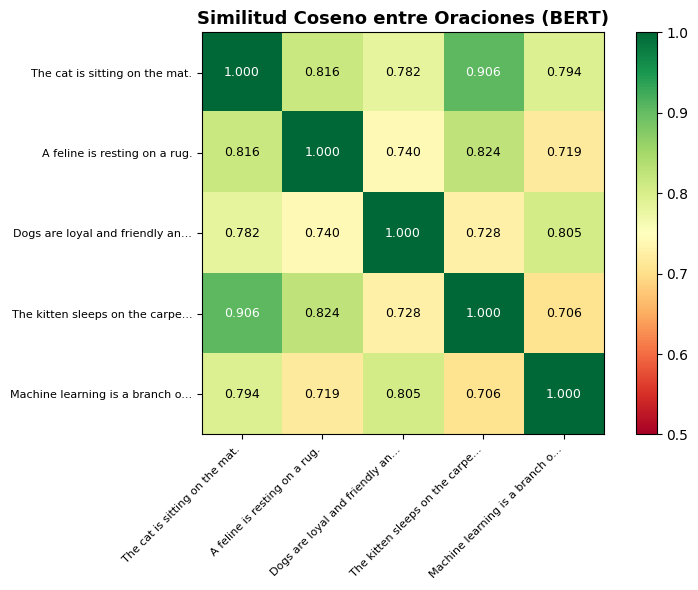


📊 Observaciones:
  'cat on mat' vs 'feline on rug': 0.816 (alta - sinónimos)
  'cat on mat' vs 'kitten sleeps': 0.906 (alta - tema similar)
  'cat on mat' vs 'dogs loyal':    0.782 (media - animales)
  'cat on mat' vs 'machine learning': 0.794 (baja - tema diferente)


In [30]:
from transformers import AutoTokenizer, AutoModel
import torch.nn.functional as F

# --- Similitud Semántica ---
print("=" * 60)
print("SIMILITUD SEMÁNTICA CON EMBEDDINGS")
print("=" * 60)

# Cargar modelo y tokenizer
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
modelo_bert = AutoModel.from_pretrained(model_name)
modelo_bert.eval()

def obtener_embedding(texto, tokenizer, modelo):
    """Obtiene el embedding de una oración usando BERT [CLS]."""
    inputs = tokenizer(texto, return_tensors="pt", truncation=True,
                       padding=True, max_length=128)
    with torch.no_grad():
        outputs = modelo(**inputs)
    # Usar el token [CLS] (primera posición) como representación
    cls_embedding = outputs.last_hidden_state[:, 0, :]
    return cls_embedding

# Oraciones de prueba
oraciones = [
    "The cat is sitting on the mat.",          # 0
    "A feline is resting on a rug.",           # 1 (similar a 0)
    "Dogs are loyal and friendly animals.",     # 2 (tema diferente)
    "The kitten sleeps on the carpet.",        # 3 (similar a 0)
    "Machine learning is a branch of AI.",      # 4 (tema muy diferente)
]

# Calcular embeddings
embeddings = []
for oracion in oraciones:
    emb = obtener_embedding(oracion, tokenizer, modelo_bert)
    embeddings.append(emb)

embeddings_tensor = torch.cat(embeddings, dim=0)  # (5, 768)

# Normalizar para similitud coseno
embeddings_norm = F.normalize(embeddings_tensor, p=2, dim=1)

# Matriz de similitud
similarity_matrix = torch.mm(embeddings_norm, embeddings_norm.t()).numpy()

# Visualizar
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(similarity_matrix, cmap='RdYlGn', vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(oraciones)))
ax.set_yticks(range(len(oraciones)))

labels_cortas = [s[:30] + '...' if len(s) > 30 else s for s in oraciones]
ax.set_xticklabels(labels_cortas, fontsize=8, rotation=45, ha='right')
ax.set_yticklabels(labels_cortas, fontsize=8)
ax.set_title('Similitud Coseno entre Oraciones (BERT)', fontsize=13, fontweight='bold')

for i in range(len(oraciones)):
    for j in range(len(oraciones)):
        ax.text(j, i, f'{similarity_matrix[i][j]:.3f}',
                ha='center', va='center', fontsize=9,
                color='white' if similarity_matrix[i][j] > 0.85 else 'black')

plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

print("\n📊 Observaciones:")
print(f"  'cat on mat' vs 'feline on rug': {similarity_matrix[0][1]:.3f} (alta - sinónimos)")
print(f"  'cat on mat' vs 'kitten sleeps': {similarity_matrix[0][3]:.3f} (alta - tema similar)")
print(f"  'cat on mat' vs 'dogs loyal':    {similarity_matrix[0][2]:.3f} (media - animales)")
print(f"  'cat on mat' vs 'machine learning': {similarity_matrix[0][4]:.3f} (baja - tema diferente)")

### 10.7 Ejemplo: Tokenización Comparada (BERT vs GPT)

Entender cómo los modelos dividen el texto en tokens es fundamental.

In [31]:
from transformers import BertTokenizer, GPT2Tokenizer

# --- Comparación de Tokenización ---
print("=" * 60)
print("COMPARACIÓN DE TOKENIZACIÓN: BERT vs GPT-2")
print("=" * 60)

bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
gpt2_tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

textos_test = [
    "Hello, how are you?",
    "Transformers revolutionized NLP",
    "Supercalifragilisticexpialidocious",
    "The embedding dimensionality is 768",
    "I love machine learning!",
]

print(f"\n{'Texto':<40} | {'BERT tokens':<35} | {'GPT-2 tokens'}")
print("-" * 120)

for texto in textos_test:
    bert_tokens = bert_tokenizer.tokenize(texto)
    gpt2_tokens = gpt2_tokenizer.tokenize(texto)

    bert_str = ' '.join(bert_tokens)[:33]
    gpt2_str = ' '.join(gpt2_tokens)[:33]

    print(f"{texto:<40} | {bert_str:<35} | {gpt2_str}")

# Comparación detallada
print(f"\n\n{'Propiedad':<25} | {'BERT':<25} | {'GPT-2'}")
print("-" * 80)
print(f"{'Algoritmo':<25} | {'WordPiece':<25} | {'BPE (Byte Pair Encoding)'}")
print(f"{'Vocab size':<25} | {bert_tokenizer.vocab_size:<25,} | {gpt2_tokenizer.vocab_size:,}")
print(f"{'Token especial inicio':<25} | {'[CLS]':<25} | {'(ninguno, usa <|endoftext|>)'}")
print(f"{'Token de máscara':<25} | {'[MASK]':<25} | {'(no tiene, no usa MLM)'}")
print(f"{'Case sensitive':<25} | {'No (uncased)':<25} | {'Sí'}")
print(f"{'Sub-word prefix':<25} | {'## (ej: ##ing)':<25} | {'Ġ (ej: Ġthe)'}")

COMPARACIÓN DE TOKENIZACIÓN: BERT vs GPT-2

Texto                                    | BERT tokens                         | GPT-2 tokens
------------------------------------------------------------------------------------------------------------------------
Hello, how are you?                      | hello , how are you ?               | Hello , Ġhow Ġare Ġyou ?
Transformers revolutionized NLP          | transformers revolution ##ized nl   | Transform ers Ġrevolution ized ĠN
Supercalifragilisticexpialidocious       | super ##cal ##if ##rag ##ilis ##t   | Super cal if rag il ist ice xp ia
The embedding dimensionality is 768      | the em ##bed ##ding dimensional #   | The Ġembed ding Ġdimension ality 
I love machine learning!                 | i love machine learning !           | I Ġlove Ġmachine Ġlearning !


Propiedad                 | BERT                      | GPT-2
--------------------------------------------------------------------------------
Algoritmo                 | WordPie

### 10.8 Ejemplo: Visualizar Atención de un Modelo Pre-entrenado

Veamos los patrones de atención aprendidos por BERT en texto real.

VISUALIZACIÓN DE ATENCIÓN DE BERT PRE-ENTRENADO


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texto: 'The cat sat on the mat because it was tired'
Tokens: ['[CLS]', 'the', 'cat', 'sat', 'on', 'the', 'mat', 'because', 'it', 'was', 'tired', '[SEP]']

Arquitectura de atención:
  Capas: 12
  Cabezas por capa: 12
  Secuencia: 12 tokens


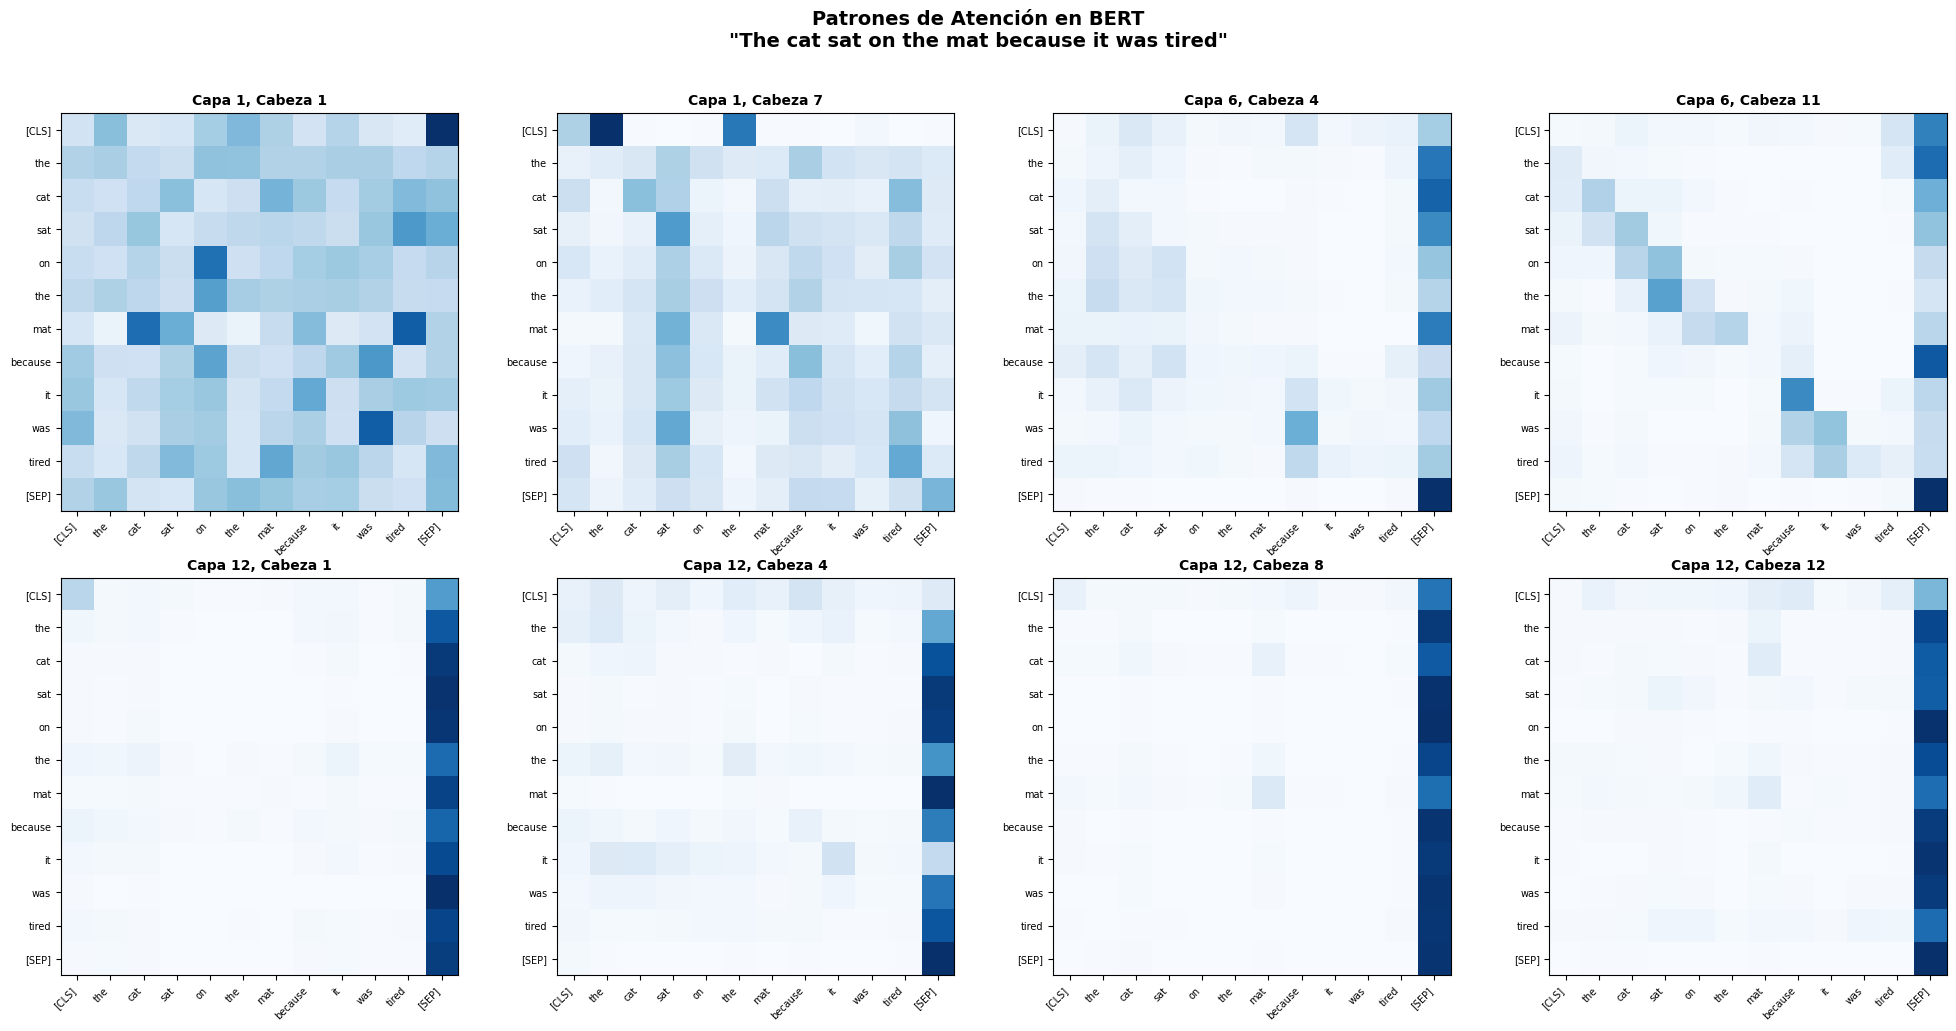


📊 ¿A quién atiende 'it' (pronombre)?
  Capa  1: 'because' (0.204)  'tired' (0.145)  '[CLS]' (0.122)  
  Capa  6: '[SEP]' (0.480)  'tired' (0.159)  'because' (0.089)  
  Capa 12: '[SEP]' (0.721)  'it' (0.059)  'the' (0.035)  

💡 En capas profundas, 'it' debería atender más a 'cat' (su referente)


In [33]:
from transformers import BertModel, BertTokenizer
import matplotlib.pyplot as plt
import numpy as np

# --- Visualización de Atención de BERT ---
print("=" * 60)
print("VISUALIZACIÓN DE ATENCIÓN DE BERT PRE-ENTRENADO")
print("=" * 60)

# Cargar modelo con atención
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
modelo = BertModel.from_pretrained('bert-base-uncased', output_attentions=True)
modelo.eval()

# Tokenizar una oración
texto = "The cat sat on the mat because it was tired"
inputs = tokenizer(texto, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

# Forward pass
with torch.no_grad():
    outputs = modelo(**inputs)

# outputs.attentions: tuple de (batch, heads, seq, seq) por cada capa
# BERT-base tiene 12 capas × 12 cabezas
attentions = outputs.attentions  # 12 capas

print(f"Texto: '{texto}'")
print(f"Tokens: {tokens}")
print(f"\nArquitectura de atención:")
print(f"  Capas: {len(attentions)}")
print(f"  Cabezas por capa: {attentions[0].shape[1]}")
print(f"  Secuencia: {attentions[0].shape[2]} tokens")

# Visualizar atención de diferentes capas y cabezas
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

layer_head_pairs = [
    (0, 0, "Capa 1, Cabeza 1"),
    (0, 6, "Capa 1, Cabeza 7"),
    (5, 3, "Capa 6, Cabeza 4"),
    (5, 10, "Capa 6, Cabeza 11"),
    (11, 0, "Capa 12, Cabeza 1"),
    (11, 3, "Capa 12, Cabeza 4"),
    (11, 7, "Capa 12, Cabeza 8"),
    (11, 11, "Capa 12, Cabeza 12"),
]

for idx, (layer, head, title) in enumerate(layer_head_pairs):
    row, col = idx // 4, idx % 4
    attn = attentions[layer][0, head].numpy()

    im = axes[row, col].imshow(attn, cmap='Blues', vmin=0)
    axes[row, col].set_title(title, fontsize=10, fontweight='bold')

    if len(tokens) <= 12:
        axes[row, col].set_xticks(range(len(tokens)))
        axes[row, col].set_yticks(range(len(tokens)))
        axes[row, col].set_xticklabels(tokens, fontsize=7, rotation=45, ha='right')
        axes[row, col].set_yticklabels(tokens, fontsize=7)

plt.suptitle(f'Patrones de Atención en BERT\n"{texto}"',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Atención promedio sobre una palabra clave
print("\n📊 ¿A quién atiende 'it' (pronombre)?")
it_idx = tokens.index('it')
for layer_idx in [0, 5, 11]:
    attn_avg = attentions[layer_idx][0, :, it_idx, :].mean(dim=0).numpy()
    top_3 = np.argsort(attn_avg)[-3:][::-1]
    print(f"  Capa {layer_idx+1:2d}: ", end="")
    for t in top_3:
        print(f"'{tokens[t]}' ({attn_avg[t]:.3f})  ", end="")
    print()

print("\n💡 En capas profundas, 'it' debería atender más a 'cat' (su referente)")

## 11. Resumen y Conclusiones

### Lo que aprendimos:

| Tema | Descripción |
|------|------------|
| **Motivación** | Los Transformers reemplazan la recurrencia por atención pura, permitiendo paralelización |
| **Self-Attention** | $\text{Attention}(Q,K,V) = \text{softmax}(QK^T/\sqrt{d_k})V$ |
| **Multi-Head** | Múltiples cabezas capturan diferentes tipos de relaciones |
| **Positional Encoding** | Sinusoides inyectan información posicional sin recurrencia |
| **Encoder** | Self-Attention bidireccional + FFN (comprensión) |
| **Decoder** | Self-Attention causal + Cross-Attention + FFN (generación) |
| **BERT** | Solo Encoder → comprensión (clasificación, QA, NER) |
| **GPT** | Solo Decoder → generación (texto, código, razonamiento) |

### Arquitectura del paper original vs modelos modernos:

| Componente | Paper Original | BERT-base | GPT-2 | GPT-3 |
|-----------|---------------|-----------|-------|-------|
| $d_{model}$ | 512 | 768 | 768 | 12,288 |
| Cabezas | 8 | 12 | 12 | 96 |
| Capas | 6 | 12 | 12 | 96 |
| $d_{ff}$ | 2048 | 3072 | 3072 | 49,152 |
| Parámetros | ~65M | ~110M | ~1.5B | ~175B |

### Ideas clave:
1. **La atención es todo lo que necesitas** - El mecanismo de atención es suficiente para capturar dependencias de cualquier rango
2. **Escalar funciona** - Más datos + más parámetros = mejor rendimiento (scaling laws)
3. **Pre-entrenar + Fine-tunar** - El paradigma dominante: pre-entrenar en texto general, ajustar para tareas específicas
4. **Prompt Engineering** - Con modelos suficientemente grandes (GPT-3+), se pueden resolver tareas sin fine-tuning

---

### Referencias

1. Vaswani, A., et al. (2017). **"Attention Is All You Need"**. NeurIPS.
2. Devlin, J., et al. (2018). **"BERT: Pre-training of Deep Bidirectional Transformers"**. NAACL.
3. Radford, A., et al. (2019). **"Language Models are Unsupervised Multitask Learners"** (GPT-2).
4. Brown, T., et al. (2020). **"Language Models are Few-Shot Learners"** (GPT-3). NeurIPS.
5. Hugging Face. **Transformers Documentation**: https://huggingface.co/docs/transformers
